# Premier League forecast | 2026/27
**Match scores, the title race and an audit of the first 110 results**  
Research snapshot · 24 November 2026 · Emmanuel Okudzeto

How much does knowing the two clubs improve a score forecast? This report fits separate attacking and defensive strengths for each club, compares them with a league-average forecast and simulates the table. Each score is the single most likely scoreline. The most likely outcome can differ because many scorelines produce the same outcome.

## Reproduce the analysis
Run the notebook from top to bottom with Python 3, pandas, NumPy, SciPy, scikit-learn, matplotlib and IPython. The first run downloads public data into `pl_data/`. To evaluate a later snapshot, set a new cutoff and refresh the cache. The final cell exports the full fixture audit to CSV.

## Findings · 24 November 2026

**Arsenal lead the model's title race at 76.6%.** Their preseason probability was 44.6%. With 28 points earned, their mean simulated finish is 82.0 points. Man City are the closest challenger at 15.9%.

Across 110 completed games, the reconstructed preseason model picked **57 outcomes** and **13 exact scores**. The league-average model picked 48 outcomes and 12 exact scores. Outcome log loss was 1.023 for the club model and 1.078 for the baseline. These 110 games cover only the opening part of the season.

In [1]:
from pathlib import Path
from urllib.request import urlopen
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import poisson, skellam
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import PoissonRegressor
from IPython.display import display

CUTOFF = pd.Timestamp('2026-11-23')  # inclusive, UK match date
REFRESH = False
CACHE = Path('pl_data')
CACHE.mkdir(exist_ok=True)

def fetch(name, url):
    path = CACHE / name
    if REFRESH or not path.exists():
        payload = urlopen(url, timeout=45).read()
        path.write_bytes(payload)
    return path

def season(year):
    code = f'{year % 100:02}{(year + 1) % 100:02}'
    path = fetch(code + '.csv', f'https://www.football-data.co.uk/mmz4281/{code}/E0.csv')
    data = pd.read_csv(path, encoding='utf-8-sig', usecols=['Date','HomeTeam','AwayTeam','FTHG','FTAG'])
    data.columns = ['date','home','away','hg','ag']
    data['date'] = pd.to_datetime(data.date, dayfirst=True, format='mixed')
    return data.dropna().assign(season=year)

history = pd.concat([season(year) for year in range(2020, 2026)], ignore_index=True)
assert history.groupby('season').size().eq(380).all()
played = season(2026).query('date <= @CUTOFF')
feed = pd.read_json(fetch('fixtures.json','https://fixturedownload.com/feed/json/epl-2026'))
fixtures = feed[['RoundNumber','DateUtc','HomeTeam','AwayTeam']].copy()
fixtures.columns = ['round','kickoff_utc','home','away']
fixtures[['home','away']] = fixtures[['home','away']].replace({'Man Utd':'Man United','Spurs':'Tottenham'})
fixtures['kickoff_utc'] = pd.to_datetime(fixtures.kickoff_utc, utc=True)
keys = ['home','away']
assert len(fixtures) == 380 and len(fixtures.drop_duplicates(keys)) == 380
games = fixtures.merge(played[keys + ['hg','ag']], on=keys, how='left', validate='one_to_one')
assert games.hg.count() == len(played)
games = games.sort_values('kickoff_utc').reset_index(drop=True)
print(f'{len(history):,} historical matches | {len(played)} current results | {games.hg.isna().sum()} remaining')

2,280 historical matches | 110 current results | 270 remaining


## Estimating goals
Each match supplies two training observations, one for each team's goals. The logarithm of the scoring rate is an intercept plus an attack effect, an opponent defence effect and a home advantage. L2 regularisation shrinks sparse estimates. A club with no training history receives zero attack and defence offsets. Returning clubs retain their recency-weighted history. Match weights halve every 365 days. The penalty and decay are fixed modelling choices.

In [2]:
def features(matches, home_side):
    scorer, opponent = ('home','away') if home_side else ('away','home')
    return [dict(attack=a, defence=d, at_home=int(home_side))
            for a, d in zip(matches[scorer], matches[opponent])]

def fit_rates(train, origin, target):
    assert train.date.max() < origin
    weights = 0.5 ** ((origin - train.date).dt.days.to_numpy() / 365)
    encoder = DictVectorizer()
    design = encoder.fit_transform(features(train, True) + features(train, False))
    model = PoissonRegressor(alpha=0.006, max_iter=500, tol=1e-8)
    model.fit(design, np.r_[train.hg, train.ag], sample_weight=np.tile(weights, 2))
    return tuple(model.predict(encoder.transform(features(target, side))) for side in (True, False))

def forecast(rates):
    h, a = rates
    return pd.DataFrame({
        'home_rate':h, 'away_rate':a, 'pick_h':np.floor(h).astype(int),
        'pick_a':np.floor(a).astype(int), 'P(H)':skellam.sf(0,h,a),
        'P(D)':skellam.pmf(0,h,a), 'P(A)':skellam.cdf(-1,h,a)})

def evaluate(pred, actual):
    h, a = actual.hg.to_numpy(), actual.ag.to_numpy()
    truth = np.where(h>a, 0, np.where(h==a, 1, 2))
    prob = pred[['P(H)','P(D)','P(A)']].to_numpy()
    exact = (pred.pick_h.to_numpy()==h) & (pred.pick_a.to_numpy()==a)
    correct = prob.argmax(axis=1)==truth
    return dict(matches=len(h), exact_hits=exact.sum(), outcome_hits=correct.sum(),
                exact_pct=round(100*exact.mean(),1), outcome_pct=round(100*correct.mean(),1),
                log_loss=round(-np.log(prob[np.arange(len(h)),truth]).mean(),3))

def compare(train, test, origin):
    model = forecast(fit_rates(train, origin, test))
    weights = 0.5 ** ((origin - train.date).dt.days / 365)
    average = tuple(np.full(len(test),np.average(train[c],weights=weights)) for c in ['hg','ag'])
    return {'Club model': evaluate(model,test), 'League average': evaluate(forecast(average),test)}

records = []
for year in [2023,2024,2025,2026]:
    test = played if year == 2026 else history.query('season == @year')
    scores = compare(history.query('season < @year'), test, test.date.min())
    for name, metrics in scores.items():
        records.append(dict(season=f'{year}/{str(year+1)[2:]}', model=name, **metrics))
metrics = pd.DataFrame(records)
display(metrics)

,season,model,matches,exact_hits,outcome_hits,exact_pct,outcome_pct,log_loss
0,2023/24,Club model,380,42,215,11.1,56.6,0.944
1,2023/24,League average,380,38,175,10.0,46.1,1.056
2,2024/25,Club model,380,46,184,12.1,48.4,1.021
3,2024/25,League average,380,45,155,11.8,40.8,1.081
4,2025/26,Club model,380,48,180,12.6,47.4,1.034
5,2025/26,League average,380,47,162,12.4,42.6,1.083
6,2026/27,Club model,110,13,57,11.8,51.8,1.023
7,2026/27,League average,110,12,48,10.9,43.6,1.078


Each row above uses an expanding training window ending before that season kicks off. The league-average baseline uses the same recency weights and home advantage but treats all clubs alike. Lower log loss rewards assigning more probability to the outcome that occurred. Exact hits require both goal counts to match. The current-season audit reconstructs predictions using only historical matches. It does not establish that these forecasts were published before kickoff.

In [3]:
pre = forecast(fit_rates(history, played.date.min(), games))
updated = forecast(fit_rates(pd.concat([history,played]), CUTOFF + pd.Timedelta(days=1), games))
mask = games.hg.notna()
def score_text(home, away):
    return home.astype(int).astype(str) + '–' + away.astype(int).astype(str)

audit = games.copy()
audit['preseason_score'] = score_text(pre.pick_h,pre.pick_a)
audit['actual'] = ''
audit.loc[mask,'actual'] = score_text(games.loc[mask,'hg'],games.loc[mask,'ag'])
audit['forecast_score'] = audit.preseason_score
audit.loc[~mask,'forecast_score'] = score_text(updated.pick_h,updated.pick_a)[~mask]
audit['forecast_basis'] = np.where(mask,'preseason reconstruction','updated after cutoff')
for col in ['home_rate','away_rate','P(H)','P(D)','P(A)']:
    audit[col] = np.where(mask,pre[col],updated[col])
audit['score_probability'] = (poisson.pmf(np.floor(audit.home_rate),audit.home_rate) *
                              poisson.pmf(np.floor(audit.away_rate),audit.away_rate))
cols = ['round','home','away','forecast_score','actual','P(H)','P(D)','P(A)','score_probability']
display(audit.loc[mask,cols].tail(10).round(3))
display(audit.loc[~mask,cols].head(10).round(3))

,round,home,away,forecast_score,actual,P(H),P(D),P(A),score_probability
100,11,Man City,Fulham,2–0,1–1,0.668,0.194,0.138,0.115
101,11,Coventry,Crystal Palace,1–1,3–2,0.417,0.263,0.320,0.125
102,11,Chelsea,Leeds,1–1,1–4,0.527,0.232,0.241,0.109
103,11,Tottenham,Ipswich,2–1,2–0,0.647,0.189,0.165,0.097
104,11,Bournemouth,Nott'm Forest,1–1,2–0,0.444,0.252,0.304,0.119
105,11,Aston Villa,Sunderland,1–1,0–0,0.490,0.257,0.253,0.122
106,11,Newcastle,Arsenal,1–1,2–2,0.249,0.242,0.509,0.115
107,11,Hull,Brighton,1–1,2–0,0.366,0.253,0.382,0.119
108,11,Liverpool,Man United,1–1,4–0,0.525,0.220,0.255,0.098
109,11,Brentford,Everton,1–1,4–0,0.468,0.259,0.274,0.123


,round,home,away,forecast_score,actual,P(H),P(D),P(A),score_probability
110,12,Nott'm Forest,Chelsea,1–1,,0.376,0.253,0.372,0.119
111,12,Leeds,Coventry,1–1,,0.542,0.228,0.230,0.107
112,12,Man United,Brentford,1–1,,0.403,0.239,0.358,0.109
113,12,Ipswich,Aston Villa,1–1,,0.256,0.222,0.522,0.100
114,12,Everton,Liverpool,1–1,,0.271,0.256,0.473,0.122
115,12,Sunderland,Tottenham,1–1,,0.367,0.277,0.356,0.131
116,12,Fulham,Bournemouth,1–1,,0.380,0.264,0.356,0.126
117,12,Brighton,Newcastle,1–1,,0.510,0.228,0.262,0.104
118,12,Crystal Palace,Hull,1–1,,0.322,0.284,0.394,0.132
119,12,Arsenal,Man City,1–1,,0.467,0.258,0.275,0.123


## Who wins the league?
The preseason simulation draws scores for every fixture. The November simulation locks in the completed scores, refits team strengths and draws the remaining fixtures. Both use 10,000 independent seasons. Teams receive three points for a win and one for a draw. Ties use goal difference, then goals scored, then a random draw as an approximation for deeper tiebreakers. The interval covers the middle 80% of simulated points totals.

In [4]:
def simulate(pred, lock_results, draws=10000):
    rng = np.random.default_rng(20261124)
    clubs = sorted(games.home.unique())
    index = {team:i for i,team in enumerate(clubs)}
    shape = (draws,len(clubs))
    points, gd, gf = [np.zeros(shape,dtype=int) for _ in range(3)]
    live_points = np.zeros(len(clubs),dtype=int)
    for i,g in games.iterrows():
        h,a = index[g.home],index[g.away]
        if lock_results and pd.notna(g.hg):
            x,y = int(g.hg),int(g.ag)
            live_points[h] += 3*(x>y)+(x==y)
            live_points[a] += 3*(y>x)+(x==y)
        else:
            x = rng.poisson(pred.home_rate[i],draws)
            y = rng.poisson(pred.away_rate[i],draws)
        points[:,h] += 3*(x>y)+(x==y)
        points[:,a] += 3*(y>x)+(x==y)
        gd[:,h] += x-y
        gd[:,a] += y-x
        gf[:,h] += x
        gf[:,a] += y
    order = np.lexsort((rng.random(shape),gf,gd,points),axis=1)[:,::-1]
    title = np.bincount(order[:,0],minlength=len(clubs))/draws
    assert np.isclose(title.sum(),1)
    return pd.DataFrame({'club':clubs,'earned':live_points,'mean_pts':points.mean(axis=0),
                         'p10':np.percentile(points,10,axis=0),'p90':np.percentile(points,90,axis=0),
                         'title_pct':100*title}).set_index('club')

opening = simulate(pre,False)
race = simulate(updated,True).join(opening.title_pct.rename('preseason_pct'))
race = race.sort_values(['title_pct','mean_pts'],ascending=False)
display(race.round(1))

,earned,mean_pts,p10,p90,title_pct,preseason_pct
club,,,,,,
Arsenal,28,82.0,74.0,90.0,76.6,44.6
Man City,22,73.2,65.0,82.0,15.9,45.9
Liverpool,21,68.5,60.0,77.0,4.7,6.2
Brighton,22,65.8,57.0,74.0,2.5,0.4
Brentford,17,57.0,48.0,65.1,0.1,0.2
Bournemouth,18,56.0,47.0,65.0,0.1,0.2
Aston Villa,14,53.2,45.0,62.0,0.0,0.4
Chelsea,16,55.3,47.0,64.0,0.0,0.6
Leeds,17,52.8,44.0,61.0,0.0,0.0


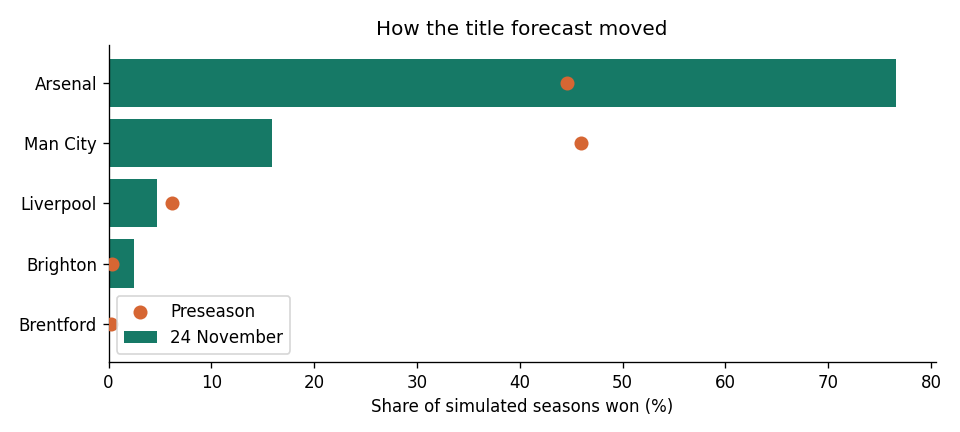

In [5]:
fig, ax = plt.subplots(figsize=(8,3.6))
contenders = race.head(5).iloc[::-1]
ax.barh(contenders.index, contenders.title_pct,color='#167966',label='24 November')
ax.scatter(contenders.preseason_pct,contenders.index,color='#d66633',s=55,label='Preseason',zorder=3)
ax.set_xlabel('Share of simulated seasons won (%)')
ax.set_title('How the title forecast moved')
ax.spines[['top','right']].set_visible(False)
ax.legend()
fig.tight_layout()
display(fig)
plt.close(fig)

## Interpretation and limitations
A scoreline is a narrow bet on two integers. Outcome probability sums across all scorelines that give the same winner or draw. Compare exact-score accuracy with its baseline and use log loss to judge the probability forecasts. The title percentages condition on fitted team strengths. Injuries, transfers, manager changes and uncertainty in those estimates could widen the race. The two goal counts are modelled independently, which can misprice low-scoring draws. Points deductions are outside the simulation.

## Fixture ledger
The table below pairs every completed match with its preseason reconstruction and shows an updated prediction for every remaining match. The CSV also includes kickoff time, the original preseason score and the estimated scoring rates. Future fixture dates can move. To preserve a genuine forward test, archive this CSV before the next kickoff and compare that unchanged copy with the next results.

In [6]:
audit.to_csv('premier_league_forecasts_2026_27.csv', index=False)
with pd.option_context('display.max_rows',400):
    display(audit[cols].round(3))

,round,home,away,forecast_score,actual,P(H),P(D),P(A),score_probability
0,1,Arsenal,Coventry,2–0,3–0,0.688,0.190,0.122,0.126
1,1,Hull,Man United,1–1,2–0,0.345,0.247,0.408,0.115
2,1,Everton,Crystal Palace,1–1,2–0,0.410,0.283,0.306,0.132
3,1,Ipswich,Sunderland,1–1,2–1,0.260,0.257,0.483,0.122
4,1,Nott'm Forest,Leeds,1–1,0–1,0.467,0.251,0.283,0.119
5,1,Brentford,Tottenham,1–1,3–0,0.484,0.229,0.286,0.104
6,1,Brighton,Aston Villa,1–1,4–0,0.415,0.249,0.337,0.117
7,1,Man City,Bournemouth,2–0,2–1,0.650,0.195,0.155,0.104
8,1,Newcastle,Liverpool,1–1,2–2,0.360,0.230,0.410,0.101
9,1,Fulham,Chelsea,1–1,2–3,0.362,0.257,0.381,0.122


**Data sources**  
Historical and current full-time results come from [Football-Data.co.uk](https://www.football-data.co.uk/englandm.php). Fixtures come from [FixtureDownload](https://fixturedownload.com/feed/json/epl-2026). The latest round can also be checked against [PLStats](https://plstats.uk/matches/). The results feed takes precedence for completed scores.